<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Chart Rendering](https://github.com/Query-farm/vgi-chart)

Render query results as line, bar, pie, scatter, and histogram PNG charts with JFreeChart.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-chart/blob/main/notebooks/01_choose_the_denominator.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-chart/blob/main/notebooks/README.md)


## 01 · Choose the denominator before drawing the chart

Which region has the highest failure rate? An average of weekly percentages answers a different question from failures divided by all requests. We make both calculations in SQL, then ask the **real Java chart worker** to render a time series and a grouped comparison as PNG BLOBs. Python displays those returned images; it does not redraw the analytical charts.

**All observations are synthetic.** Twelve rows describe four invented weeks of requests and failures in Aster, Briar and Cedar. Every request belongs to one region-week cell and is counted once. This example concerns aggregation choices, not a real service’s reliability.

### Choose a reporting horizon

`WEEKS` is an integer from 2 to 4; default 4. It includes weeks 1 through `WEEKS`, inclusive, from the same fixed fixture. The final experiment uses only the first two weeks. Restart and run all after changing the parameter.

In [1]:
WEEKS = 4  # inclusive synthetic reporting horizon; integer 2–4

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.25":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.25"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

from vgi_notebooks import check_runtime  # noqa: E402

check_runtime()

In [3]:
if type(WEEKS) is not int or not 2 <= WEEKS <= 4:
    raise ValueError("WEEKS must be an integer from 2 to 4.")
from vgi_notebooks import connect, prepare
from vgi_notebooks.presentation import prose
from IPython.display import display

prepare("chart")
from chart_example import show_worker_png  # noqa: E402

session = connect(globals())
SOURCE = (
    "Source: 12 synthetic region-week counts · vgi-chart v0.4.0 · JFreeChart 1.5.6 / Java 21.0.8"
)

### Attach the released chart renderer

The short literal launcher uses published **v0.4.0**, checks its immutable JAR digest and runs managed **Java 21.0.8** from a separate locked environment. It never uses system Java or compiles source. First use downloads Python, the shared package, VGI, Java and the JAR; rendering thereafter is local CPU work. The shared connection uses an empty temporary secret directory and disables persistent secrets.

This worker returns **PNG**, not SVG. Folded presentation code validates the PNG signature/dimensions and embeds the **unchanged worker bytes** in an SVG frame containing explanation and provenance. The analytical marks remain raster content. The notebook does not redraw them in Python. Raw PNGs are saved under ignored `artifacts/worker-png/` and the published SVG links retain their embedded PNGs.

These small inputs fit one Arrow batch. The renderer can emit a chart-so-far for each batch on larger inputs; we require one complete image, rather than silently selecting the last result. An empty input emits zero image rows.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'chart' (TYPE vgi,
    LOCATION 'uv run --locked --no-project --python 3.13 chart_release.py v0.4.0');

,Success


### Match the rendering interface to the question

Use `chart_types` to distinguish an ordered weekly trend from a category comparison. Its argument names tell us to supply `x/y/series` for a line and `category/value/series` for bars. This discovery table guides the two calls below; neither renderer chooses a statistical denominator for us.

In [5]:
%%sql capabilities <<
SELECT chart_type,category,column_arguments,summary FROM chart.main.chart_types
WHERE chart_type IN ('chart_line','chart_bar') ORDER BY chart_type;

In [6]:
display(capabilities)
arguments = dict(zip(capabilities.chart_type, capabilities.column_arguments))
assert arguments == {"chart_bar": "category, value, series", "chart_line": "x, y, series"}
prose(
    "The catalog separates ordered trends from category comparisons. We use a line for weeks, bars for weighting rules, and keep the same region series in both."
)

,chart_type,category,column_arguments,summary
0,chart_bar,categorical-comparisons,"category, value, series",Vertical bar chart comparing a numeric measure...
1,chart_line,trends-and-relationships,"x, y, series",Line chart of a measure over an ordered or tim...


The catalog separates ordered trends from category comparisons. We use a line for weeks, bars for weighting rules, and keep the same region series in both.

### Build and inspect the weekly observations

The table grain is one region per week. Request volume changes over time, particularly in Briar. Compute each weekly percentage from its own numerator and positive denominator before plotting. No missing value is replaced with zero.

In [7]:
%%sql
CREATE TABLE observations AS
SELECT * FROM (VALUES
    (1, 'Aster', 1000, 20), (2, 'Aster', 1200, 36),
    (3, 'Aster', 800, 64),  (4, 'Aster', 1400, 112),
    (1, 'Briar', 100, 10),  (2, 'Briar', 100, 10),
    (3, 'Briar', 500, 15),  (4, 'Briar', 500, 15),
    (1, 'Cedar', 400, 16),  (2, 'Cedar', 500, 20),
    (3, 'Cedar', 600, 24),  (4, 'Cedar', 700, 28)
) AS t(week, region, requests, failures);

CREATE TABLE weekly AS
SELECT *, 100.0 * failures / requests AS failure_pct
FROM observations WHERE week BETWEEN 1 AND {{WEEKS}};

SELECT week, region, requests, failures, failure_pct
FROM weekly ORDER BY region, week;

,week,region,requests,failures,failure_pct
0,1,Aster,1000,20,2.0
1,2,Aster,1200,36,3.0
2,3,Aster,800,64,8.0
3,4,Aster,1400,112,8.0
4,1,Briar,100,10,10.0
5,2,Briar,100,10,10.0
6,3,Briar,500,15,3.0
7,4,Briar,500,15,3.0
8,1,Cedar,400,16,4.0
9,2,Cedar,500,20,4.0


### Render the weekly pattern through SQL

The chart function consumes a relation and returns PNG bytes. Column names become axis labels; here they include the percentage unit. Categorical week labels avoid implying fractional observation weeks. The ordered input fixes a consistent region legend. Materialize the render once, then read its local BLOB for display. Both images in this notebook come from the worker.

The worker can emit a chart-so-far for each input batch. This deliberately small relation is validated to return **one** PNG row; the display helper refuses multiple images rather than guessing which partial chart is complete. It also verifies the PNG format and requested 1100 × 640 pixel dimensions.

In [8]:
%%sql
CREATE TABLE weekly_png AS
SELECT png FROM chart.main.chart_line(
    (SELECT 'Week ' || CAST(week AS VARCHAR) AS "Week", failure_pct AS "Failure rate (%)", region AS "Region"
     FROM weekly ORDER BY region, week),
    x := 'Week', y := 'Failure rate (%)', series := 'Region',
    title := 'Weekly failure rates | synthetic weeks 1-{{WEEKS}}', width := 1100, height := 640
);

,Count


In [9]:
%%sql line_blob <<
SELECT png FROM weekly_png;

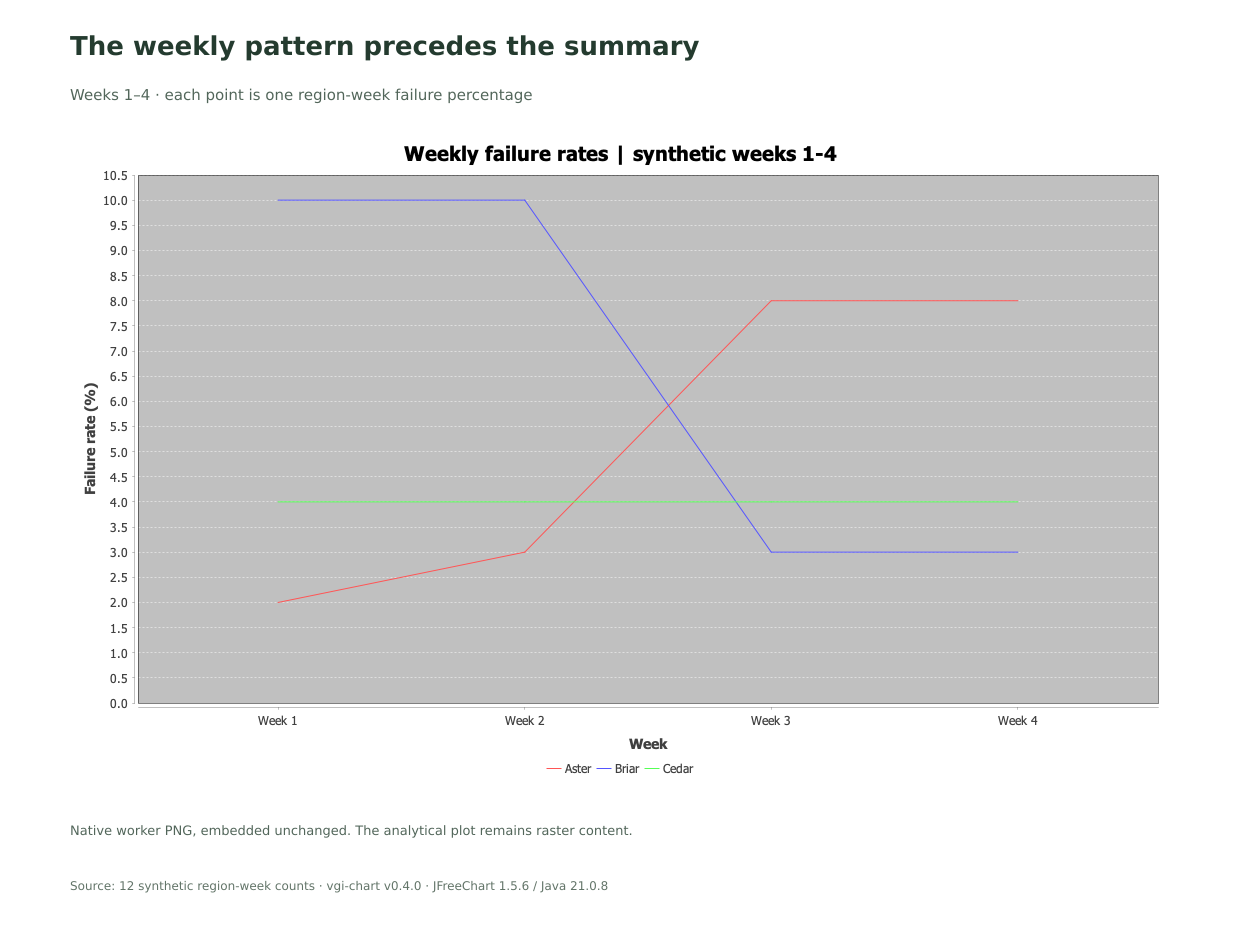

{'png_rows': 1,
 'png_bytes': 37088,
 'width_px': 1100,
 'height_px': 640,
 'worker_png_sha256': '0946a2079588e8866bd9ae22176f48b3b8b586867e22259111a82078596d4f5e',
 'embedded_bytes_unchanged': True,
 'native_format': 'PNG',
 'presentation_format': 'SVG with raster image'}

In [10]:
line_details = show_worker_png(
    line_blob,
    f"weekly-rates-{WEEKS}",
    "The weekly pattern precedes the summary",
    f"Weeks 1–{WEEKS} · each point is one region-week failure percentage",
    SOURCE,
)
display(line_details)

### Two valid summaries, two different weights

The **average weekly rate** gives each week equal weight: it describes the mean percentage of a uniformly selected week. The **pooled request rate** gives each request equal weight: total failures divided by total requests. It is also the request-weighted average of weekly percentages. These are different estimands; the right one depends on whether the question is about weeks or requests.

Aggregate explicitly before passing data to the renderer. A bar chart expects one value per category-series pair; duplicate pairs in this worker replace earlier values rather than summing them.

In [11]:
%%sql
CREATE TABLE regional_rates AS
SELECT region, count(*) AS weeks_observed, sum(requests) AS requests,
       sum(failures) AS failures,
       avg(failure_pct) AS average_week_pct,
       100.0 * sum(failures) / sum(requests) AS pooled_request_pct,
       sum(failure_pct * requests) / sum(requests) AS weighted_week_pct
FROM weekly GROUP BY region;

CREATE TABLE comparison AS
SELECT region, 'Average week' AS weighting, average_week_pct AS failure_pct FROM regional_rates
UNION ALL
SELECT region, 'Pooled requests' AS weighting, pooled_request_pct AS failure_pct FROM regional_rates;

,Count


In [12]:
%%sql rates <<
SELECT region, weeks_observed, requests, failures, average_week_pct, pooled_request_pct,
       average_week_pct - pooled_request_pct AS averaging_gap_percentage_points
FROM regional_rates ORDER BY region;

In [13]:
display(rates)

,region,weeks_observed,requests,failures,average_week_pct,pooled_request_pct,averaging_gap_percentage_points
0,Aster,4,4400.0,232.0,5.25,5.272727,-0.022727
1,Briar,4,1200.0,50.0,6.50,4.166667,2.333333
2,Cedar,4,2200.0,88.0,4.00,4.000000,0.000000


In [14]:
weekly_leader = rates.loc[rates.average_week_pct.idxmax()]
pooled_leader = rates.loc[rates.pooled_request_pct.idxmax()]
prose(
    f"Across synthetic weeks **1–{WEEKS}**, **{weekly_leader.region}** has the highest average weekly rate "
    f"at **{weekly_leader.average_week_pct:.2f}%**. **{pooled_leader.region}** has the highest pooled "
    f"request rate at **{pooled_leader.pooled_request_pct:.2f}%**. "
    f"The pooled calculation covers **{int(rates.requests.sum()):,} requests** and "
    f"**{int(rates.failures.sum()):,} failures** across the three regions."
)
briar = rates.set_index("region").loc["Briar"]
prose(
    f"For Briar, averaging weekly percentages gives **{briar.average_week_pct:.2f}%**, while "
    f"pooling requests gives **{briar.pooled_request_pct:.2f}%**: a gap of "
    f"**{briar.averaging_gap_percentage_points:+.2f} percentage points**. "
    "Inspect the weekly counts to see which weeks receive more weight in the pooled result."
)

Across synthetic weeks **1–4**, **Briar** has the highest average weekly rate at **6.50%**. **Aster** has the highest pooled request rate at **5.27%**. The pooled calculation covers **7,800 requests** and **370 failures** across the three regions.

For Briar, averaging weekly percentages gives **6.50%**, while pooling requests gives **4.17%**: a gap of **+2.33 percentage points**. Inspect the weekly counts to see which weeks receive more weight in the pooled result.

### Render the comparison from the aggregated relation

The category identifies the weighting rule, the series identifies the region and the value is a percentage. The region order matches the line chart so its colors and labels stay consistent. This chart visualizes the SQL table above; the renderer does not choose the denominator.

In [15]:
%%sql
CREATE TABLE comparison_png AS
SELECT png FROM chart.main.chart_bar(
    (SELECT weighting AS "Weighting rule", failure_pct AS "Failure rate (%)", region AS "Region"
     FROM comparison ORDER BY region, weighting),
    category := 'Weighting rule', value := 'Failure rate (%)', series := 'Region',
    title := 'The denominator changes the comparison | synthetic weeks 1-{{WEEKS}}',
    width := 1100, height := 640
);

,Count


In [16]:
%%sql bar_blob <<
SELECT png FROM comparison_png;

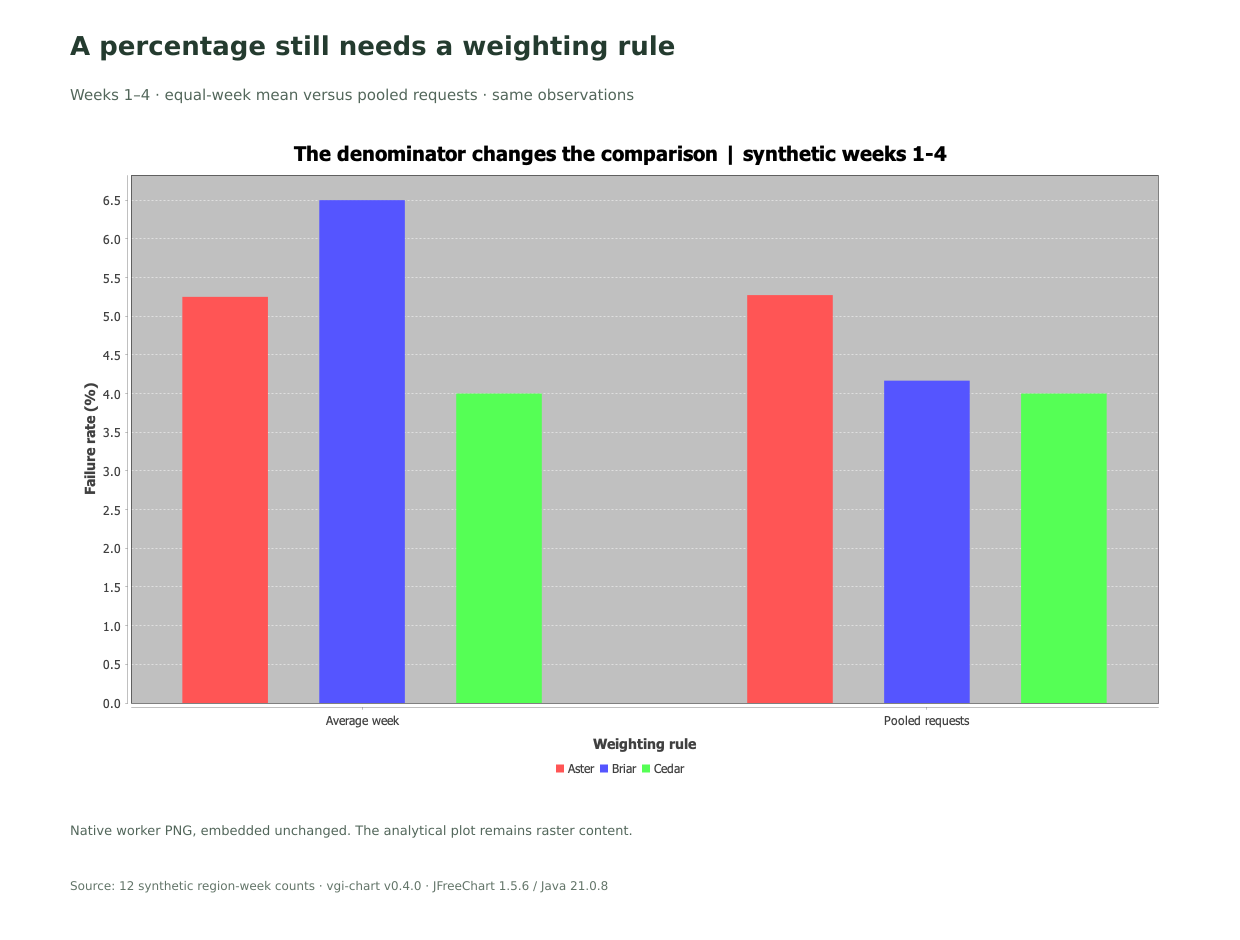

{'png_rows': 1,
 'png_bytes': 33847,
 'width_px': 1100,
 'height_px': 640,
 'worker_png_sha256': '3d5c8eda82843c9d5c247f21d8ba151262798a2fc2010f78a3b2ce3503f156c0',
 'embedded_bytes_unchanged': True,
 'native_format': 'PNG',
 'presentation_format': 'SVG with raster image'}

In [17]:
bar_details = show_worker_png(
    bar_blob,
    f"weighting-comparison-{WEEKS}",
    "A percentage still needs a weighting rule",
    f"Weeks 1–{WEEKS} · equal-week mean versus pooled requests · same observations",
    SOURCE,
)
display(bar_details)

### Verify the denominators and rendered artifacts

Check the input grain, numerator bounds, equivalence of the two request-weighted formulas and one-row image outputs. PNG bytes need not be identical across operating systems or Java font environments; format, dimensions and analytical values are the useful invariants.

In [18]:
%%sql checks <<
SELECT 'one observation per region-week' AS check_name,
       count(*) = count(DISTINCT (region, week)) AS passed FROM weekly
UNION ALL
SELECT 'positive denominators and bounded failures', bool_and(requests > 0 AND failures BETWEEN 0 AND requests) FROM weekly
UNION ALL
SELECT 'pooled rate equals request-weighted weekly rate',
       max(abs(pooled_request_pct - weighted_week_pct)) < 1e-10 FROM regional_rates
UNION ALL
SELECT 'unique chart category-series pairs', count(*) = count(DISTINCT (weighting, region)) FROM comparison
UNION ALL
SELECT 'one valid line PNG', count(*) = 1 AND bool_and(png[1:4] = '\x89PNG'::BLOB AND octet_length(png) > 100) FROM weekly_png
UNION ALL
SELECT 'one valid bar PNG', count(*) = 1 AND bool_and(png[1:4] = '\x89PNG'::BLOB AND octet_length(png) > 100) FROM comparison_png;

In [19]:
display(checks)
assert checks.passed.fillna(False).all(), "A grain, denominator or PNG invariant failed."

,check_name,passed
0,one observation per region-week,True
1,positive denominators and bounded failures,True
2,pooled rate equals request-weighted weekly rate,True
3,unique chart category-series pairs,True
4,one valid line PNG,True
5,one valid bar PNG,True


### Experiment: shorten the horizon

Change only **`WEEKS` from 4 to 2**. Predict that Briar's two summaries become equal because its first two weeks have equal request counts. Check the weekly plot, weighting comparison and result-derived ranking explanation. Fewer weeks also means fewer requests; this is a change in the reporting population, not evidence of a performance improvement.

Use the separate experiment command in the README, then compare with the saved default. The second notebook holds all four weeks fixed and changes only histogram binning.

In [20]:
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-chart](https://github.com/Query-farm/vgi-chart)
